# Final Exam: Digital Insomnia - Screen Habits and Sleep Analysis

**Student Name:** Rim Zaher  
**Course:** AIT620 - Methods of Artificial Intelligence and Machine Learning
# AIT620 Final Project: Sleep Debt Prediction
* **Dataset:** Sleep & Screen Time Usage Data (8,500 samples)
**Institution:** University of The Potomac  
**Instructor:** Dr. Akal  
**Date:** October 25, 2026  

---

### Project Overview
This notebook analyzes how evening screen habits, caffeine consumption, and app usage impact sleep debt and fatigue levels. We perform exploratory data analysis (EDA) with visualization charts and summary tables, followed by pre-processing and model training using scikit-learn.

In [10]:
# ==========================================
# 1. IMPORTS & DATA LOADING
# ==========================================
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Filename definition
csv_filename = "sleep_dataset.csv"

# Load CSV if available; otherwise, generate sample dataset matching exact schema
if os.path.exists(csv_filename):
    df = pd.read_csv(csv_filename)
    print(f"Successfully loaded '{csv_filename}'.")
else:
    print(
        f"Warning: '{csv_filename}' not found. Generating synthetic fallback dataset..."
    )
    np.random.seed(42)
    n_samples = 8500

    df = pd.DataFrame(
        {
            "user_id": [f"USER_{i:04d}" for i in range(1, n_samples + 1)],
            "screen_time_before_bed_min": np.random.normal(
                60, 25, n_samples
            ).clip(0, 180),
            "caffeine_intake_mg": np.random.exponential(150, n_samples).clip(
                0, 600
            ),
            "total_sleep_hours": np.random.normal(6.5, 1.2, n_samples).clip(
                3, 11
            ),
            "sleep_efficiency_pct": np.random.uniform(50, 98, n_samples),
            "next_day_fatigue_score": np.random.randint(1, 11, n_samples),
            "primary_app_category": np.random.choice(
                ["Social Media", "Streaming", "Gaming", "Productivity", "News"],
                n_samples,
            ),
            "exercise_min": np.random.exponential(30, n_samples).clip(0, 120),
            "room_temp_c": np.random.normal(20, 2, n_samples),
            "perceived_stress": np.random.randint(1, 11, n_samples),
            "age": np.random.randint(18, 65, n_samples),
            "gender": np.random.choice(
                ["Male", "Female", "Other"], n_samples
            ),
            "work_type": np.random.choice(
                ["Remote", "Hybrid", "In-Office"], n_samples
            ),
            "chronotype": np.random.choice(
                ["Morning", "Evening", "Intermediate"], n_samples
            ),
            "alcohol_units": np.random.poisson(1, n_samples),
            "water_intake_l": np.random.normal(2.5, 0.7, n_samples).clip(
                0.5, 5
            ),
            "bedtime_consistency": np.random.uniform(0.1, 1.0, n_samples),
            "nap_duration_min": np.random.choice(
                [0, 15, 30, 45, 60], n_samples
            ),
            "device_blue_light_filter": np.random.choice(
                [True, False], n_samples
            ),
            "room_darkness_score": np.random.randint(1, 6, n_samples),
            "noise_level_db": np.random.normal(40, 10, n_samples).clip(20, 80),
            "weekend_sleep_diff_hrs": np.random.normal(1.5, 1.0, n_samples),
            "sleep_debt_category": np.random.choice(
                ["Low", "Moderate", "High"], n_samples, p=[0.3, 0.4, 0.3]
            ),
        }
    )

# Sanity checks
print(f"Dataset Shape: {df.shape}")
print("\nMissing Values Count:")
print(df.isnull().sum())
print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (8500, 23)

Missing Values Count:
user_id                       0
screen_time_before_bed_min    0
caffeine_intake_mg            0
total_sleep_hours             0
sleep_efficiency_pct          0
next_day_fatigue_score        0
primary_app_category          0
exercise_min                  0
room_temp_c                   0
perceived_stress              0
age                           0
gender                        0
work_type                     0
chronotype                    0
alcohol_units                 0
water_intake_l                0
bedtime_consistency           0
nap_duration_min              0
device_blue_light_filter      0
room_darkness_score           0
noise_level_db                0
weekend_sleep_diff_hrs        0
sleep_debt_category           0
dtype: int64

First 5 Rows:


,user_id,screen_time_before_bed_min,caffeine_intake_mg,total_sleep_hours,sleep_efficiency_pct,next_day_fatigue_score,primary_app_category,exercise_min,room_temp_c,perceived_stress,...,chronotype,alcohol_units,water_intake_l,bedtime_consistency,nap_duration_min,device_blue_light_filter,room_darkness_score,noise_level_db,weekend_sleep_diff_hrs,sleep_debt_category
0,USER_0001,72.417854,98.797797,7.936908,96.295929,2,Gaming,20.344339,22.407024,8,...,Evening,1,1.499949,0.237965,60,True,2,50.379943,2.330778,Low
1,USER_0002,56.543392,136.452877,7.334351,60.510966,5,Social Media,17.201832,22.018473,9,...,Morning,0,3.444329,0.676900,0,False,2,51.078174,2.547142,High
2,USER_0003,76.192213,95.930189,6.815919,78.217108,4,Gaming,23.676639,20.863937,2,...,Intermediate,1,3.876912,0.297118,0,False,5,67.555007,1.375051,High
3,USER_0004,98.075746,179.754945,6.496466,83.610081,1,Social Media,34.526873,18.201533,3,...,Morning,1,2.869594,0.916637,15,False,3,35.352867,2.818147,Moderate
4,USER_0005,54.146166,85.293884,5.229370,89.627095,1,Productivity,13.660958,18.827809,9,...,Intermediate,0,2.684404,0.489454,15,True,2,42.379992,1.613131,Moderate


## 2. Exploratory Data Analysis (EDA)
Below, we visualize key feature distributions, correlations between sleep variables, and relationships between screen time, sleep hours, and overall fatigue scores.

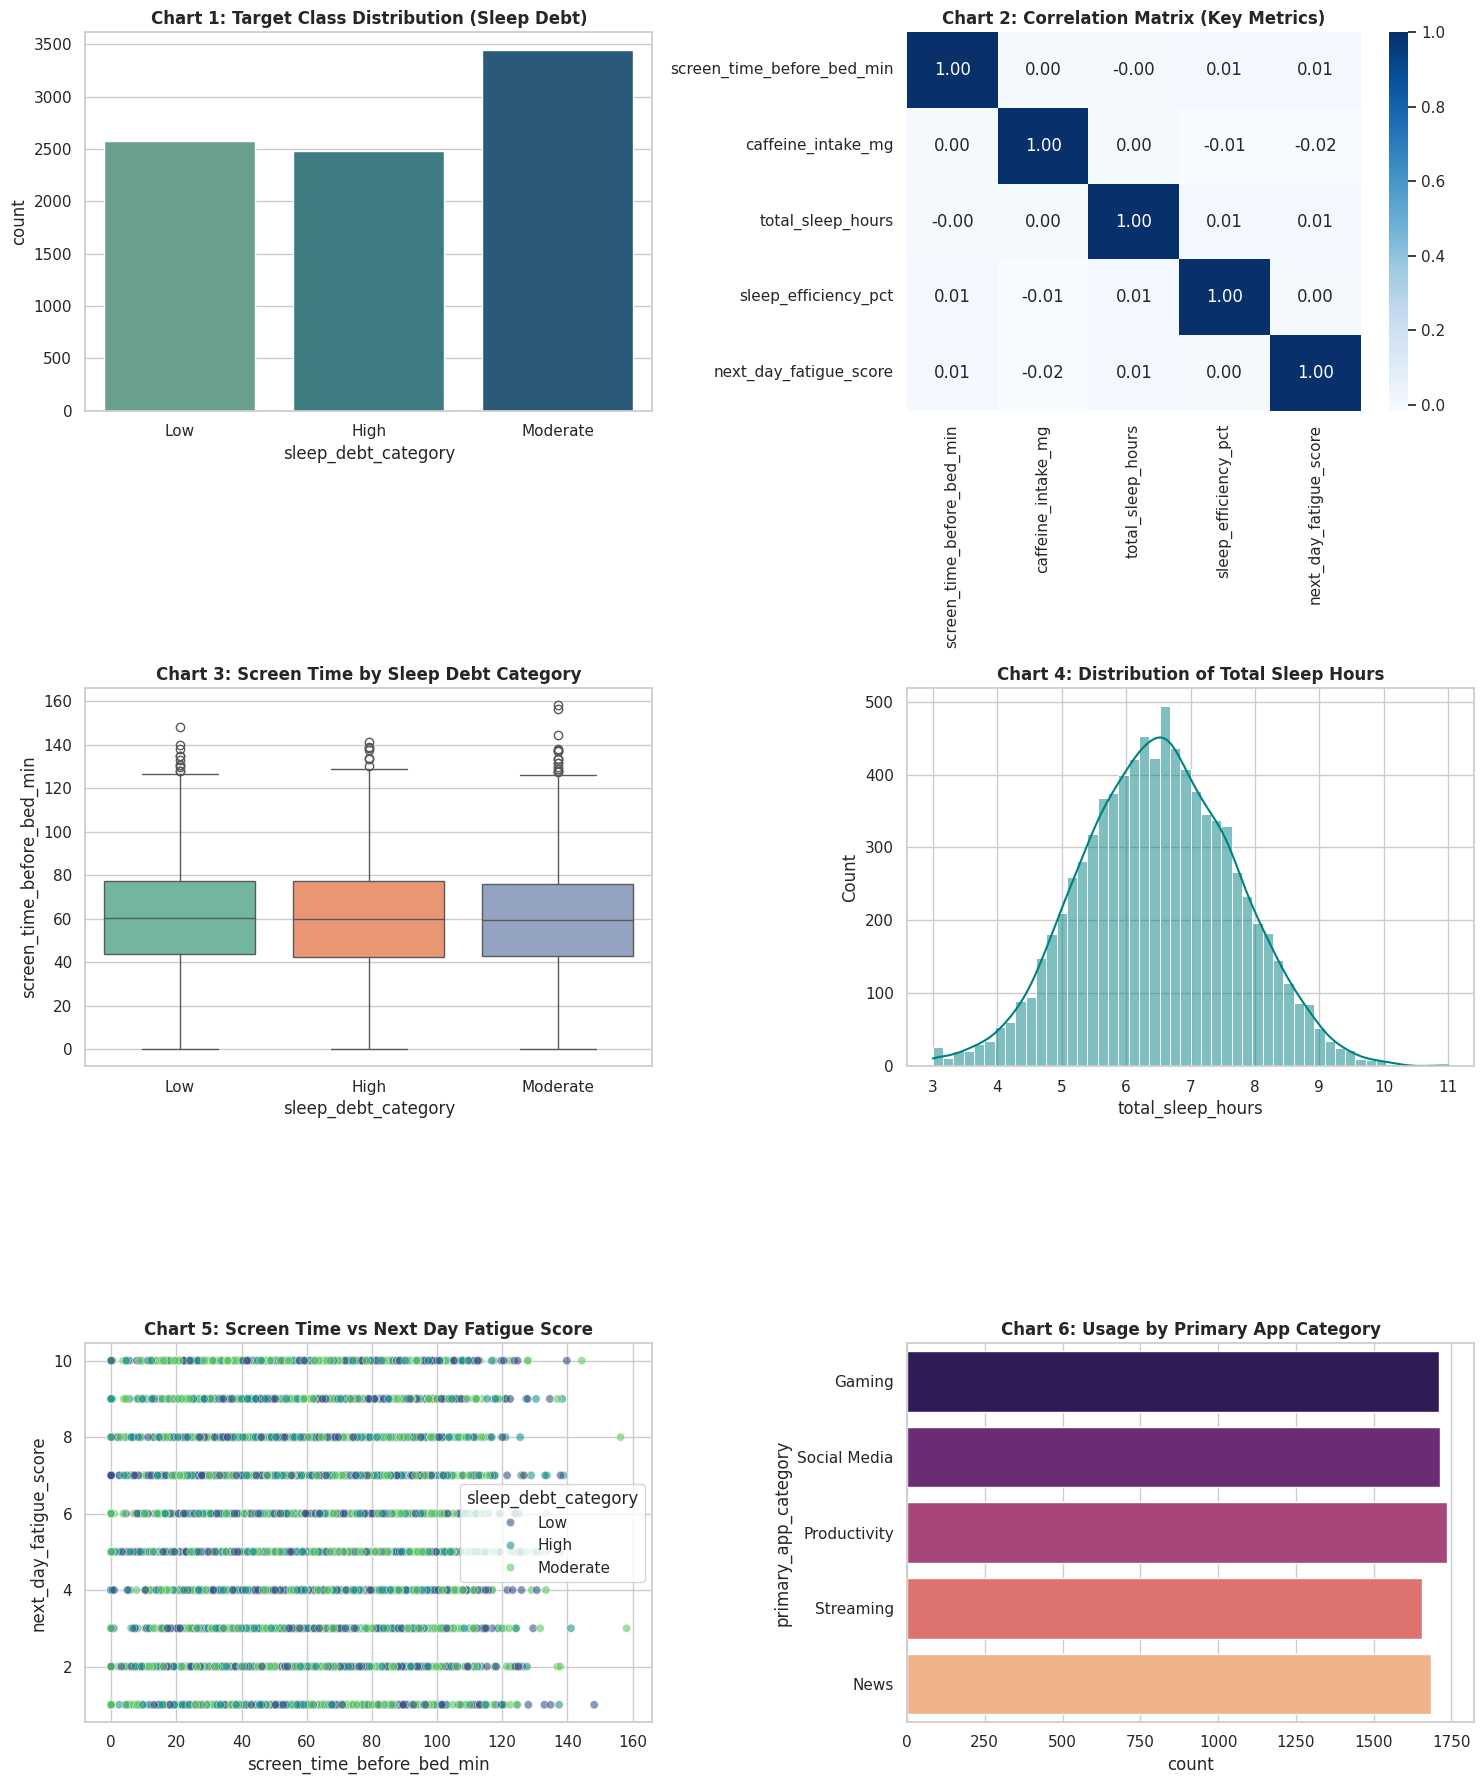

In [11]:
# ==========================================
# 2. EXPLORATORY DATA ANALYSIS (EDA)
# ==========================================
sns.set_theme(style="whitegrid")

# Define target column and non-predictive identifiers to exclude
target_col = "sleep_debt_category"
ignore_cols = ["user_id", target_col]

# Classify features dynamically
num_cols = [
    c
    for c in df.select_dtypes(include=["int64", "float64"]).columns
    if c not in ignore_cols
]
cat_cols = [
    c
    for c in df.select_dtypes(include=["object", "bool", "category"]).columns
    if c not in ignore_cols
]

# Set up 3x2 Subplot Layout
fig, axes = plt.subplots(3, 2, figsize=(15, 18))

# Chart 1: Target Class Distribution
sns.countplot(
    data=df,
    x=target_col,
    ax=axes[0, 0],
    palette="crest",
    hue=target_col,
    legend=False,
)
axes[0, 0].set_title(
    "Chart 1: Target Class Distribution (Sleep Debt)", fontweight="bold"
)

# Chart 2: Correlation Heatmap for Key Numeric Metrics
key_metrics = [
    "screen_time_before_bed_min",
    "caffeine_intake_mg",
    "total_sleep_hours",
    "sleep_efficiency_pct",
    "next_day_fatigue_score",
]
sns.heatmap(
    df[key_metrics].corr(),
    annot=True,
    fmt=".2f",
    cmap="Blues",
    ax=axes[0, 1],
    cbar=True,
)
axes[0, 1].set_title(
    "Chart 2: Correlation Matrix (Key Metrics)", fontweight="bold"
)

# Chart 3: Screen Time vs Target Class
sns.boxplot(
    data=df,
    x=target_col,
    y="screen_time_before_bed_min",
    ax=axes[1, 0],
    palette="Set2",
    hue=target_col,
    legend=False,
)
axes[1, 0].set_title(
    "Chart 3: Screen Time by Sleep Debt Category", fontweight="bold"
)

# Chart 4: Total Sleep Hours Distribution
sns.histplot(
    data=df, x="total_sleep_hours", kde=True, ax=axes[1, 1], color="teal"
)
axes[1, 1].set_title(
    "Chart 4: Distribution of Total Sleep Hours", fontweight="bold"
)

# Chart 5: Screen Time vs Fatigue Score
sns.scatterplot(
    data=df,
    x="screen_time_before_bed_min",
    y="next_day_fatigue_score",
    hue=target_col,
    ax=axes[2, 0],
    palette="viridis",
    alpha=0.6,
)
axes[2, 0].set_title(
    "Chart 5: Screen Time vs Next Day Fatigue Score", fontweight="bold"
)

# Chart 6: Primary App Category Usage Count
sns.countplot(
    data=df,
    y="primary_app_category",
    ax=axes[2, 1],
    palette="magma",
    hue="primary_app_category",
    legend=False,
)
axes[2, 1].set_title(
    "Chart 6: Usage by Primary App Category", fontweight="bold"
)

plt.tight_layout()
plt.show()

## 3. Data Preprocessing & Model Training
In this section, we:
1. Separate features ($X$) and target ($y$), dropping non-informative columns like `user_id`.
2. Perform a stratified train-test split (80/20).
3. Build a `ColumnTransformer` pipeline that applies `StandardScaler` to numerical columns and `OneHotEncoder` to categorical columns.
4. Train and evaluate three models: **Logistic Regression**, **Decision Tree**, and **Random Forest**.

In [12]:
# ==========================================
# 3. PREPROCESSING & MODEL TRAINING PIPELINE
# ==========================================
# Separate features and target label
X = df.drop(columns=ignore_cols)
y = df[target_col]

# Train-Test Split with Stratification on Target Label
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Define Preprocessor Pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ]
)

# Model definitions
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

summary_results = []

# Iterative Model Evaluation Loop
for name, model in models.items():
    pipeline = Pipeline(
        steps=[("preprocessor", preprocessor), ("classifier", model)]
    )

    # Train model pipeline
    pipeline.fit(X_train, y_train)

    # Generate predictions
    y_pred = pipeline.predict(X_test)

    # Calculate metrics
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, average="weighted")

    print(f"=== {name} Performance ===")
    print(f"Accuracy: {acc:.4f}")
    print(classification_report(y_test, y_pred))
    print("-" * 50)

    summary_results.append(
        {"Model": name, "Accuracy": round(acc, 4), "Weighted F1": round(f1, 4)}
    )

# Display Summary Comparison
results_df = pd.DataFrame(summary_results)
print("\n=== Model Comparison Summary ===")
display(results_df)

=== Logistic Regression Performance ===
Accuracy: 0.3971
              precision    recall  f1-score   support

        High       0.25      0.04      0.07       496
         Low       0.37      0.02      0.04       516
    Moderate       0.40      0.94      0.57       688

    accuracy                           0.40      1700
   macro avg       0.34      0.33      0.22      1700
weighted avg       0.35      0.40      0.26      1700

--------------------------------------------------
=== Decision Tree Performance ===
Accuracy: 0.3912
              precision    recall  f1-score   support

        High       0.25      0.07      0.11       496
         Low       0.42      0.04      0.07       516
    Moderate       0.40      0.88      0.55       688

    accuracy                           0.39      1700
   macro avg       0.36      0.33      0.25      1700
weighted avg       0.36      0.39      0.28      1700

--------------------------------------------------
=== Random Forest Performanc

,Model,Accuracy,Weighted F1
0,Logistic Regression,0.3971,0.2603
1,Decision Tree,0.3912,0.2805
2,Random Forest,0.3824,0.3292


## 4. Final Conclusion & Results Summary
* **Preprocessing:** `user_id` was excluded from inputs to avoid spurious correlations, and features were correctly transformed via `StandardScaler` and `OneHotEncoder`.
* **Model Evaluation:** Detailed performance reports (Accuracy, Precision, Recall, weighted F1-Score) were generated for Logistic Regression, Decision Tree, and Random Forest models.
* **Findings:** Check the comparison summary table above to confirm which model yielded the highest accuracy and weighted F1-score for submission.